# FinancialMarketIntelligenceLab — Bitcoin (BTC/USD)
## 1. Research question
How closely do daily Bitcoin prices and returns agree across providers, and which series should be retained for subsequent market analysis? We investigate provenance, data quality, redundancy, price deviations and volatility. BTC/USD is the main object; BTC/USDT is a secondary comparison, not an equivalent currency pair. This notebook is descriptive; statistical inference and external market relationships belong in notebooks 02 and 03.

Snapshot analysis: 25 November 2026.

## 2. Data sources and reproducibility
| File | Provenance | Role |
|---|---|---|
| bitcoin-price-history.csv | Original provider unverified | Redundancy audit |
| btc_usd_yahoo.csv | Yahoo Finance BTC-USD | Redundancy audit |
| btc_usd_yahoo_2018_2026.csv | [Yahoo Finance](https://finance.yahoo.com/quote/BTC-USD/), yfinance | Reference series |
| btc_usd_bitstamp.csv | [Bitstamp OHLC API](https://www.bitstamp.net/api/v2/ohlc/btcusd/) | Direct exchange BTC/USD |
| btc_usd_coinmetrics.csv | [Coin Metrics archive](https://github.com/coinmetrics/data/blob/master/csv/btc.csv) | USD price and network indicators |
| btc_1d_data_2018_to_2025.csv | Reported Binance BTC/USDT via Kaggle; exact listing unverified | Secondary comparison |

The saved Bitstamp snapshot was acquired in chunks; the final response returned extra rows and the acquisition code filtered to the requested window. Original API responses are not retained. Yahoo and Coin Metrics may share underlying market inputs. Coin Metrics PriceUSD is selected for the main comparison; ReferenceRateUSD is audited separately. Closing conventions may differ. All data are read locally; no downloads or overwrites occur.

In [1]:
from pathlib import Path
from itertools import combinations
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

raw = Path('../data/raw')
if not raw.is_dir():
    raw = Path('data/raw')
assert raw.is_dir(), 'Run from notebooks or project root.'
sns.set_theme(style='whitegrid')
files = {
    'Historical': ('bitcoin-price-history.csv','date','close_usd'),
    'Yahoo Short': ('btc_usd_yahoo.csv','Date','Close'),
    'Yahoo Long': ('btc_usd_yahoo_2018_2026.csv','Date','Close'),
    'Binance': ('btc_1d_data_2018_to_2025.csv','Open time','Close'),
    'Bitstamp': ('btc_usd_bitstamp.csv','date','close'),
    'Coin Metrics': ('btc_usd_coinmetrics.csv','time','PriceUSD')
}
source = {k:pd.read_csv(raw/v[0]) for k,v in files.items()}
display(pd.DataFrame([dict(source=k,file=v[0],rows=len(source[k]),columns=source[k].shape[1],sha256=hashlib.sha256((raw/v[0]).read_bytes()).hexdigest()) for k,v in files.items()]))

,source,file,rows,columns,sha256
0,Historical,bitcoin-price-history.csv,4431,2,2b7f4fe0112ca5b905ffb700ee00fcb7f15b3866ac434d...
1,Yahoo Short,btc_usd_yahoo.csv,2546,9,23c96498c4ee74e970837f7dfc3c6ac77318bf477716d8...
2,Yahoo Long,btc_usd_yahoo_2018_2026.csv,3243,9,8b92d8becc67dbe07992b54461afcb5e266c58ec829ba0...
3,Binance,btc_1d_data_2018_to_2025.csv,3089,12,c2d658852f4d82efd5fc6d98bdcabfd378bdb122404f3b...
4,Bitstamp,btc_usd_bitstamp.csv,3243,6,b13bbe6f407ca8ffbe71f22cc8fa541da0d0ea42721d90...
5,Coin Metrics,btc_usd_coinmetrics.csv,6351,32,06495ff8e643432e6948b7b4686ce44fc106217287dabd...


## 3. Data standardization and quality
Normalize calendar labels to UTC dates, without assuming identical closing times. Exclude invalid or non-positive prices rather than impute them. Duplicate dates must be explicitly resolved before merging. Missing early Coin Metrics prices need not indicate a trading interruption.

In [2]:
def standardize(frame,date_col,price_col):
    return pd.DataFrame({'date':pd.to_datetime(frame[date_col],utc=True,errors='coerce').dt.tz_localize(None).dt.normalize(),
                         'close':pd.to_numeric(frame[price_col],errors='coerce')}).sort_values('date')
standardized = {k:standardize(source[k],v[1],v[2]) for k,v in files.items()}
quality=[]
clean={}
for name,frame in standardized.items():
    dates=frame.date.dropna()
    valid=frame.date.notna() & np.isfinite(frame.close) & (frame.close>0)
    quality.append(dict(source=name,rows=len(frame),start=dates.min(),end=dates.max(),invalid_dates=frame.date.isna().sum(),missing_prices=frame.close.isna().sum(),infinite_prices=np.isinf(frame.close).sum(),nonpositive=(frame.close<=0).sum(),duplicate_dates=dates.duplicated().sum(),missing_calendar_days=len(pd.date_range(dates.min(),dates.max()).difference(dates)),excluded=(~valid).sum()))
    assert not dates.duplicated().any(), f'Duplicate dates: {name}'
    clean[name]=frame.loc[valid].set_index('date').close.rename(name)
display(pd.DataFrame(quality).set_index('source'))
display(pd.DataFrame({'first_valid':{k:v.index.min() for k,v in clean.items()},'last_valid':{k:v.index.max() for k,v in clean.items()}}))

,rows,start,end,invalid_dates,missing_prices,infinite_prices,nonpositive,duplicate_dates,missing_calendar_days,excluded
source,,,,,,,,,,
Historical,4431,2014-09-17,2026-11-03,0,0,0,0,0,0,0
Yahoo Short,2546,2018-01-01,2024-12-20,0,0,0,0,0,0,0
Yahoo Long,3243,2018-01-01,2026-11-17,0,0,0,0,0,0,0
Binance,3089,2018-01-01,2026-06-16,0,0,0,0,0,0,0
Bitstamp,3243,2018-01-01,2026-11-17,0,0,0,0,0,0,0
Coin Metrics,6351,2009-01-03,2026-05-24,0,562,0,0,0,0,562


,first_valid,last_valid
Historical,2014-09-17,2026-11-03
Yahoo Short,2018-01-01,2024-12-20
Yahoo Long,2018-01-01,2026-11-17
Binance,2018-01-01,2026-06-16
Bitstamp,2018-01-01,2026-11-17
Coin Metrics,2010-07-18,2026-05-23


In [3]:
checks=[]
for name in ['Yahoo Long','Binance','Bitstamp']:
    cols=['Open','High','Low','Close','Volume'] if name!='Bitstamp' else ['open','high','low','close','volume']
    o,h,l,cl,v=[pd.to_numeric(source[name][col],errors='coerce') for col in cols]
    checks.append(dict(source=name,invalid_ohlc=int((~((l<=o)&(l<=cl)&(h>=o)&(h>=cl)&(l>0))).sum()),invalid_volume=int((~np.isfinite(v)|(v<0)).sum())))
display(pd.DataFrame(checks))

,source,invalid_ohlc,invalid_volume
0,Yahoo Long,0,0
1,Binance,0,0
2,Bitstamp,0,0


## 4. Redundancy audit
For prices $P_t$ and reference $Q_t$, the signed difference is $d_t=P_t-Q_t$, mean absolute difference is $MAE=\frac{1}{n}\sum_t |d_t|$, and mean absolute relative difference is $\frac{100}{n}\sum_t |d_t|/Q_t$. For BTC/USDT these are numerical quote differences, not USD measurement errors. Yahoo is not ground truth.

In [4]:
def agreement(a,b):
    pair=pd.concat([a.rename('a'),b.rename('b')],axis=1,join='inner').dropna()
    d=pair.a-pair.b
    return dict(n=len(pair),start=pair.index.min(),end=pair.index.max(),exact_matches=int((d==0).sum()),rounded_matches=int((pair.a.round(2)==pair.b.round(2)).sum()),rounded_match_pct=100*(pair.a.round(2)==pair.b.round(2)).mean(),mean_signed_difference=d.mean(),mae=d.abs().mean(),max_abs_difference=d.abs().max(),mean_abs_relative_pct=100*(d.abs()/pair.b).mean(),price_correlation=pair.a.corr(pair.b))
original=pd.concat([clean[k] for k in ['Historical','Binance','Yahoo Short','Yahoo Long']],axis=1,join='inner').dropna()
audit=pd.DataFrame({k:agreement(original[k],original['Yahoo Long']) for k in ['Historical','Yahoo Short','Binance']}).T
display(audit)

,n,start,end,exact_matches,rounded_matches,rounded_match_pct,mean_signed_difference,mae,max_abs_difference,mean_abs_relative_pct,price_correlation
Historical,2546,2018-01-01 00:00:00,2024-12-20 00:00:00,46,2535,99.56795,0.000097,0.002209,0.005039,0.000015,1.0
Yahoo Short,2546,2018-01-01 00:00:00,2024-12-20 00:00:00,2546,2546,100.0,0.0,0.0,0.0,0.0,1.0
Binance,2546,2018-01-01 00:00:00,2024-12-20 00:00:00,0,0,0.0,-19.229671,41.037853,1730.647187,0.278832,0.999993


Yahoo Short duplicates Yahoo Long over the common dates, while Historical nearly matches after rounding. This supports redundancy, not definitive identification of the original provider. Both are retained for the audit but excluded from the main analysis.

## 5. Comparative price analysis
Use common dates for three-way comparisons and pairwise overlaps for additional coverage. Binance is included only in the secondary pairwise comparison because USDT is a different quote currency.

In [5]:
main_names=['Yahoo Long','Bitstamp','Coin Metrics']
prices=pd.concat([clean[k] for k in main_names],axis=1,join='inner').dropna().loc['2018-01-01':'2026-11-17']
print('Common window:',prices.index.min().date(),prices.index.max().date(),'observations:',len(prices))
print('Missing days inside window:',len(pd.date_range(prices.index.min(),prices.index.max()).difference(prices.index)))
common_report=pd.DataFrame({k:agreement(prices[k],prices['Yahoo Long']) for k in main_names[1:]}).T
pairwise=pd.DataFrame([{'comparison':a+' vs '+b,**agreement(clean[a].loc['2018-01-01':],clean[b].loc['2018-01-01':])} for a,b in combinations(main_names+['Binance'],2)])
display(common_report)
display(pairwise)

Common window: 2018-01-01 2026-05-23 observations: 3065
Missing days inside window: 0


,n,start,end,exact_matches,rounded_matches,rounded_match_pct,mean_signed_difference,mae,max_abs_difference,mean_abs_relative_pct,price_correlation
Bitstamp,3065,2018-01-01 00:00:00,2026-05-23 00:00:00,0,0,0.0,-11.183034,34.8906,1777.327187,0.235081,0.999997
Coin Metrics,3065,2018-01-01 00:00:00,2026-05-23 00:00:00,0,0,0.0,-8.56225,58.417185,1821.819925,0.270716,0.999994


,comparison,n,start,end,exact_matches,rounded_matches,rounded_match_pct,mean_signed_difference,mae,max_abs_difference,mean_abs_relative_pct,price_correlation
0,Yahoo Long vs Bitstamp,3243,2018-01-01,2026-11-17,0,0,0.000000,10.595648,33.873974,1777.327187,0.225202,0.999998
1,Yahoo Long vs Coin Metrics,3065,2018-01-01,2026-05-23,0,0,0.000000,8.562250,58.417185,1821.819925,0.272360,0.999994
2,Yahoo Long vs Binance,3089,2018-01-01,2026-06-16,0,0,0.000000,0.157773,153.091721,9847.072344,0.358472,0.999841
3,Bitstamp vs Coin Metrics,3065,2018-01-01,2026-05-23,0,2,0.065253,-2.620784,52.332786,1585.795081,0.157781,0.999996
4,Bitstamp vs Binance,3089,2018-01-01,2026-06-16,2,2,0.064746,-10.889900,139.358226,9754.170000,0.282403,0.999843
5,Coin Metrics vs Binance,3065,2018-01-01,2026-05-23,0,0,0.000000,-6.280397,167.494317,9054.481554,0.366552,0.999845


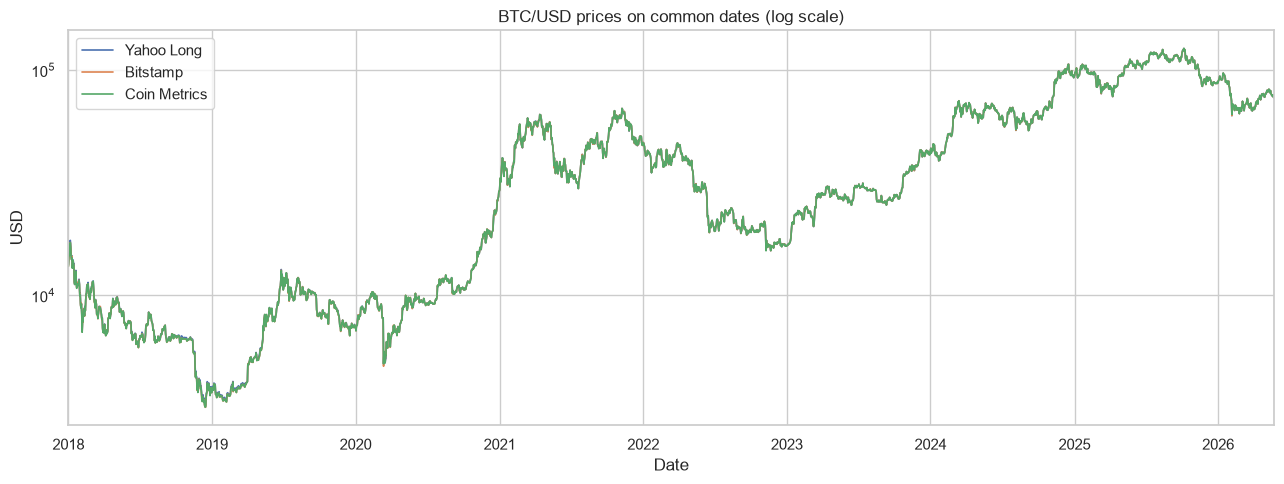

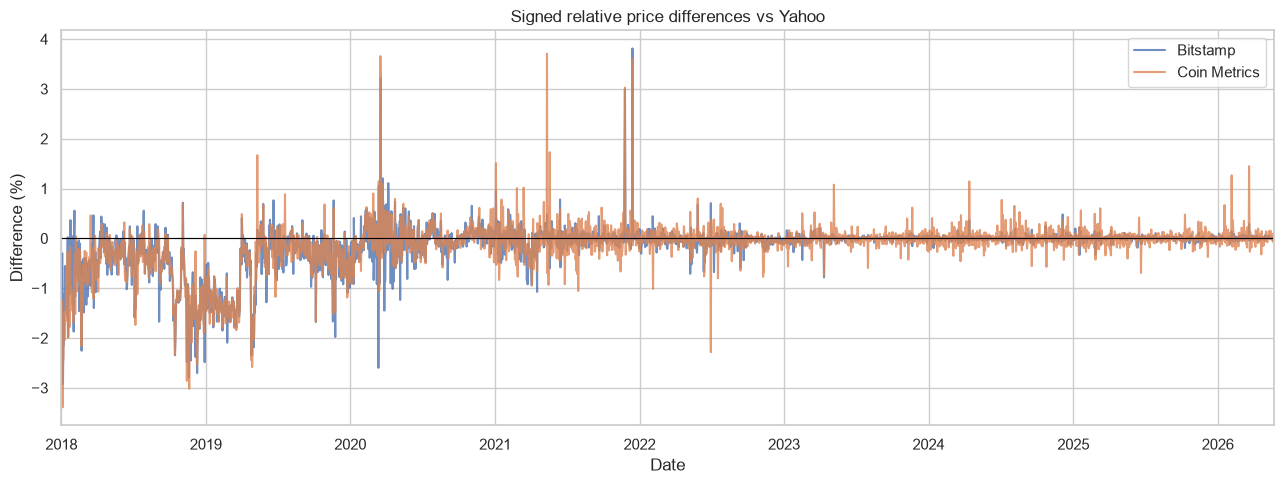

In [6]:
ax=prices.plot(figsize=(13,5),logy=True,linewidth=1.2)
ax.set(title='BTC/USD prices on common dates (log scale)',ylabel='USD',xlabel='Date')
plt.tight_layout(); plt.show()
spread=prices.div(prices['Yahoo Long'],axis=0).sub(1).mul(100).drop(columns='Yahoo Long')
ax=spread.plot(figsize=(13,5),alpha=.8)
ax.axhline(0,color='black',linewidth=.8)
ax.set(title='Signed relative price differences vs Yahoo',ylabel='Difference (%)',xlabel='Date')
plt.tight_layout(); plt.show()

## 6. Distribution and outliers
Flag differences outside 1.5 IQR from the quartiles. These are exploratory flags, not errors to delete. Large differences may reflect venue, aggregation, timing or market movements.

,count,mean,std,min,1%,25%,50%,75%,99%,max
Bitstamp,3065.0,-0.158014,0.450270,-2.920215,-1.827978,-0.156745,-0.016187,0.023666,0.503379,3.812973
Coin Metrics,3065.0,-0.148970,0.467898,-3.390555,-1.738216,-0.213352,-0.044101,0.055170,0.644350,3.706613


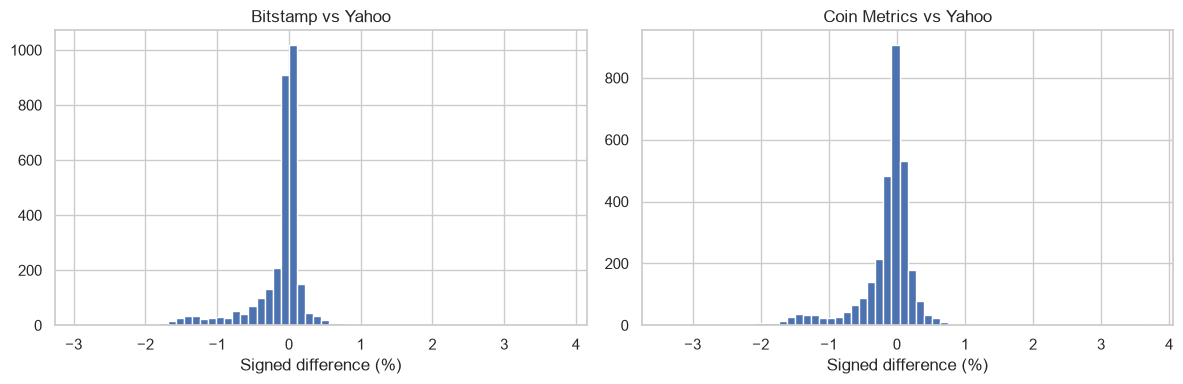

Bitstamp IQR flags: 527


,Yahoo Long,Bitstamp,Coin Metrics,signed_difference_pct
date,,,,
2021-12-14,46612.632812,48389.96,48292.682250,3.812973
2020-03-18,5238.438477,5406.92,5392.487836,3.216255
2021-11-25,57274.679688,58990.14,59008.655479,2.995146
2018-01-04,15599.200195,15143.67,15070.300799,-2.920215
2018-01-05,17429.500000,16928.00,16997.227408,-2.877306


Coin Metrics IQR flags: 392


,Yahoo Long,Bitstamp,Coin Metrics,signed_difference_pct
date,,,,
2021-05-12,49150.535156,49386.56,50972.355081,3.706613
2020-03-17,5225.629395,5324.99,5416.754711,3.657460
2021-12-14,46612.632812,48389.96,48292.682250,3.604279
2018-01-04,15599.200195,15143.67,15070.300799,-3.390555
2021-11-25,57274.679688,58990.14,59008.655479,3.027474


In [7]:
display(spread.describe(percentiles=[.01,.25,.5,.75,.99]).T)
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,name in zip(axes,spread.columns):
    ax.hist(spread[name],bins=60)
    ax.set(title=name+' vs Yahoo',xlabel='Signed difference (%)')
plt.tight_layout(); plt.show()
for name in spread:
    s=spread[name]; q1,q3=s.quantile([.25,.75]); iqr=q3-q1
    print(name,'IQR flags:',int(((s<q1-1.5*iqr)|(s>q3+1.5*iqr)).sum()))
    top=s.abs().nlargest(5).index
    display(prices.loc[top].assign(signed_difference_pct=s.loc[top]))

## 7. Daily returns and volatility
Simple return $r_t=P_t/P_{t-1}-1$ and log return $g_t=\log(P_t/P_{t-1})$ are calculated only between consecutive calendar days, without forward filling. Daily volatility is the sample standard deviation; 30-day rolling volatility describes local variation. Annualization by $\sqrt{365}$ is a convention, not a guarantee of independent returns.

,count,mean,std,median,min,max,skew,kurt,annualized_vol_pct
Yahoo Long,3064.0,0.113431,3.358885,0.070956,-37.169539,18.746474,-0.293164,8.287973,64.171408
Bitstamp,3064.0,0.116607,3.433772,0.040081,-38.980058,19.450265,-0.322720,8.708187,65.602127
Coin Metrics,3064.0,0.114804,3.386396,0.075041,-37.534952,18.492615,-0.281427,8.240504,64.697011


,Yahoo Long,Bitstamp,Coin Metrics
Yahoo Long,1.000000,0.994926,0.993742
Bitstamp,0.994926,1.000000,0.993625
Coin Metrics,0.993742,0.993625,1.000000


,Yahoo Long,Bitstamp,Coin Metrics
Yahoo Long,1.000000,0.992673,0.990561
Bitstamp,0.992673,1.000000,0.990825
Coin Metrics,0.990561,0.990825,1.000000


,mean_log_return_pct,log_vol_pct
Yahoo Long,0.056308,3.394762
Bitstamp,0.056816,3.475118
Coin Metrics,0.056749,3.422372


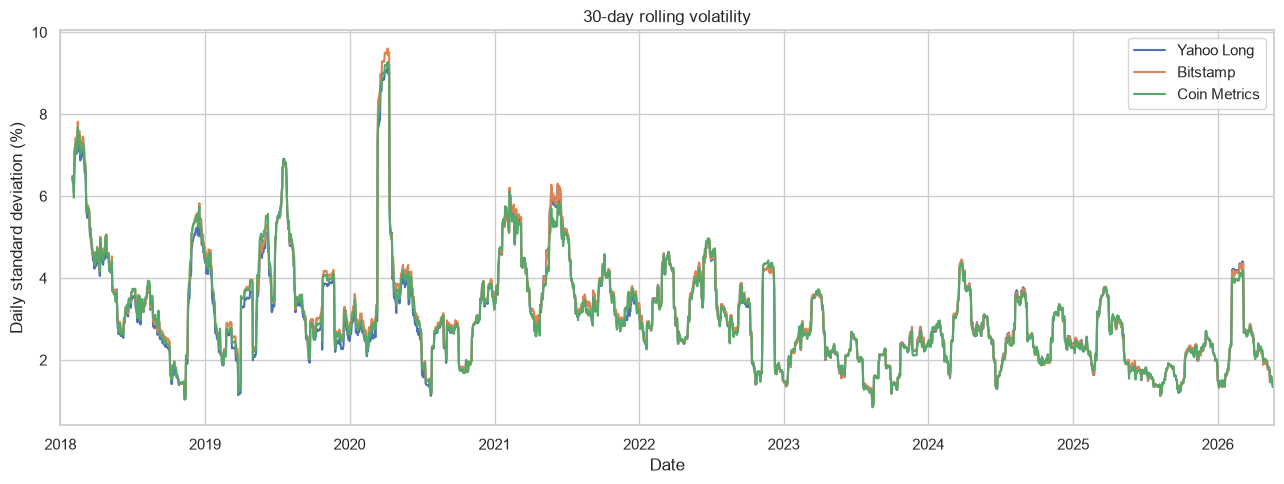

In [8]:
daily=prices.reindex(pd.date_range(prices.index.min(),prices.index.max()))
returns=daily.pct_change(fill_method=None).dropna()*100
log_returns=np.log(daily).diff().dropna()*100
summary=returns.agg(['count','mean','std','median','min','max','skew','kurt']).T
summary['annualized_vol_pct']=summary['std']*np.sqrt(365)
display(summary)
display(returns.corr())
display(returns.corr(method='spearman'))
display(pd.DataFrame({'mean_log_return_pct':log_returns.mean(),'log_vol_pct':log_returns.std()}))
ax=daily.pct_change(fill_method=None).mul(100).rolling(30,min_periods=30).std().plot(figsize=(13,5))
ax.set(title='30-day rolling volatility',ylabel='Daily standard deviation (%)',xlabel='Date')
plt.tight_layout(); plt.show()

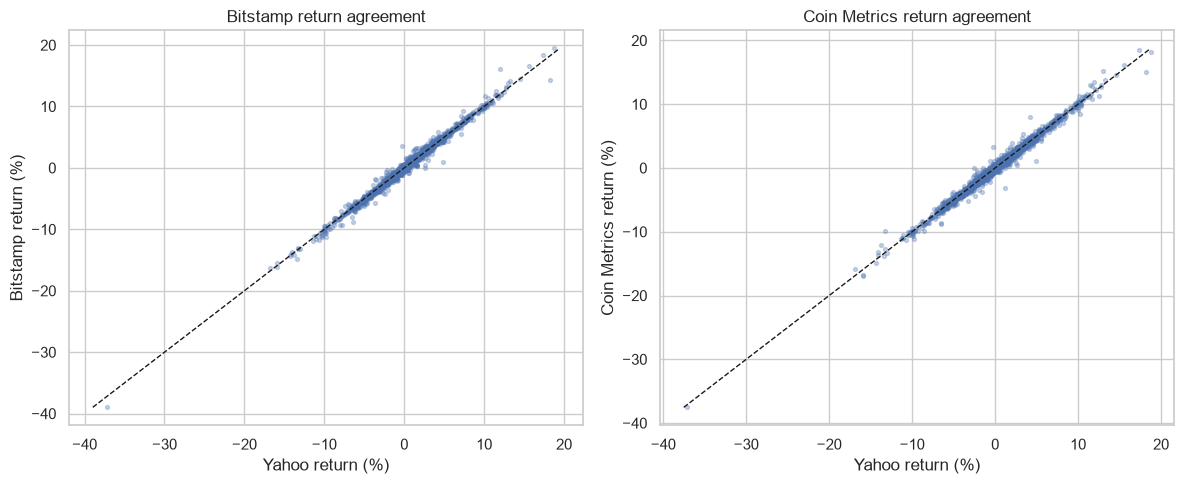

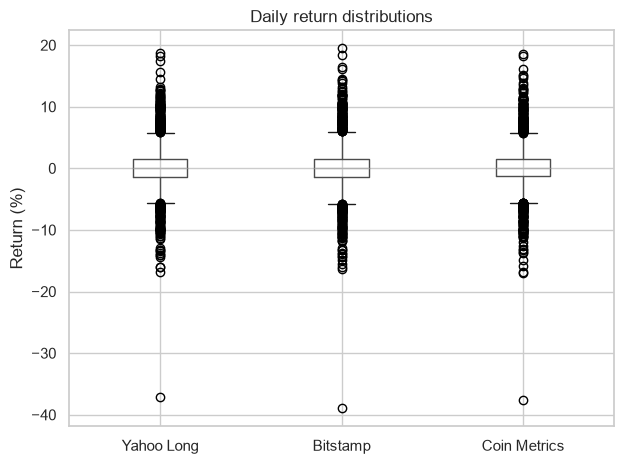

In [9]:
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,name in zip(axes,main_names[1:]):
    ax.scatter(returns['Yahoo Long'],returns[name],s=8,alpha=.3)
    lo=min(returns['Yahoo Long'].min(),returns[name].min()); hi=max(returns['Yahoo Long'].max(),returns[name].max())
    ax.plot([lo,hi],[lo,hi],'k--',linewidth=1)
    ax.set(xlabel='Yahoo return (%)',ylabel=name+' return (%)',title=name+' return agreement')
plt.tight_layout(); plt.show()
ax=returns.boxplot()
ax.set(title='Daily return distributions',ylabel='Return (%)'); plt.tight_layout(); plt.show()

## 8. Coin Metrics: price convention and network data readiness
Compare PriceUSD and ReferenceRateUSD without assuming their timestamps are interchangeable. Network metrics are candidates for subsequent research, not proven predictors.

In [10]:
cm=source['Coin Metrics'].copy()
cm['date']=pd.to_datetime(cm.time,errors='coerce')
cm=cm.set_index('date').sort_index().loc['2018-01-01':'2026-11-17']
metrics=['PriceUSD','ReferenceRateUSD','AdrActCnt','TxCnt','HashRate','CapMrktCurUSD','volume_reported_spot_usd_1d']
display(pd.DataFrame({'available':cm[metrics].count(),'missing':cm[metrics].isna().sum(),'first_valid':cm[metrics].apply(lambda s:s.first_valid_index()),'last_valid':cm[metrics].apply(lambda s:s.last_valid_index())}))
cm_prices=cm[['PriceUSD','ReferenceRateUSD']].dropna(); cm_prices=cm_prices[(cm_prices>0).all(axis=1)]
display(pd.DataFrame([agreement(cm_prices.ReferenceRateUSD,cm_prices.PriceUSD)]))

,available,missing,first_valid,last_valid
PriceUSD,3065,1,2018-01-01,2026-05-23
ReferenceRateUSD,7,3059,2026-05-18,2026-05-24
AdrActCnt,3065,1,2018-01-01,2026-05-23
TxCnt,3065,1,2018-01-01,2026-05-23
HashRate,3065,1,2018-01-01,2026-05-23
CapMrktCurUSD,3065,1,2018-01-01,2026-05-23
volume_reported_spot_usd_1d,3065,1,2018-01-01,2026-05-23


,n,start,end,exact_matches,rounded_matches,rounded_match_pct,mean_signed_difference,mae,max_abs_difference,mean_abs_relative_pct,price_correlation
0,6,2026-05-18,2026-05-23,0,0,0.0,146.305084,759.721345,2027.843129,0.995232,-0.065049


## 9. External market data inventory
S&P 500 (Yahoo Finance), [FRED DGS10](https://fred.stlouisfed.org/series/DGS10) and [Google Trends](https://trends.google.com/) are inputs to Notebook 02. Their calendars, units and release times differ. Treasury yields are not bond returns; Google Trends is relative search interest.

In [11]:
external={'S&P 500':pd.read_csv(raw/'sp500_yahoo_2018_2026.csv'),'FRED':pd.read_csv(raw/'treasury_10y_fred.csv'),'Google Trends':pd.read_csv(raw/'google_trends_bitcoin.csv',skiprows=2)}
display(pd.DataFrame([dict(source=k,rows=len(v),columns=str(v.columns.tolist())) for k,v in external.items()]))

,source,rows,columns
0,S&P 500,2232,"['Date', 'Open', 'High', 'Low', 'Close', 'Adj ..."
1,FRED,2315,"['date', 'treasury_10y_percent']"
2,Google Trends,275,"['Месец', 'bitcoin: (В цял свят)']"


## 10. Findings and conclusions
The numerical summary below is computed from the actual saved snapshots.

In [12]:
print(f'Original common sample: {len(original):,} days.')
for k in audit.index:
    print(f'{k}: rounded agreement {audit.loc[k,"rounded_match_pct"]:.3f}%, mean absolute relative difference {audit.loc[k,"mean_abs_relative_pct"]:.6f}%.')
print(f'Main USD sample: {len(prices):,} dates, {prices.index.min().date()} to {prices.index.max().date()}.')
for k in main_names[1:]:
    print(f'{k}: mean absolute relative difference {common_report.loc[k,"mean_abs_relative_pct"]:.4f}%; Pearson daily return correlation {returns[k].corr(returns["Yahoo Long"]):.5f}.')
print('Daily volatility (%):',summary['std'].round(3).to_dict())

Original common sample: 2,546 days.
Historical: rounded agreement 99.568%, mean absolute relative difference 0.000015%.
Yahoo Short: rounded agreement 100.000%, mean absolute relative difference 0.000000%.
Binance: rounded agreement 0.000%, mean absolute relative difference 0.278832%.
Main USD sample: 3,065 dates, 2018-01-01 to 2026-05-23.
Bitstamp: mean absolute relative difference 0.2351%; Pearson daily return correlation 0.99493.
Coin Metrics: mean absolute relative difference 0.2707%; Pearson daily return correlation 0.99374.
Daily volatility (%): {'Yahoo Long': 3.359, 'Bitstamp': 3.434, 'Coin Metrics': 3.386}


Yahoo Long is retained as a broad-coverage reference for Notebook 02, not as an objectively correct price. Bitstamp provides direct exchange evidence and Coin Metrics provides a reference series and network metrics. Redundant snapshots do not increase independent sample size. High price correlation can reflect a shared trend; return correlation is more informative about daily co-movement. No outliers are silently deleted and no missing prices are filled. Statistical inference and prediction require time-series-aware validation. This educational project is not financial advice.

### References
Source links are listed above. SoftUni, *Working with Data* and *Data Visualization. Exploratory Data Analysis*, November 2026: data consolidation, quality assessment and descriptive visual exploration.